In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("city_day.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("city_day.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (29531, 16)

First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


In [ ]:
print("--- DATASET INFORMATION ---")
df.info()

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- MISSING VALUE PERCENTAGES ---")
missing_percentage = (df.isnull().mean() * 100).round(2)
print(missing_percentage.sort_values(ascending=False))

--- DATASET INFORMATION ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB

--- MISSING VALUES ---
City              0
Date              0
PM2.5   

In [ ]:
print("--- PM2.5 STATISTICS ---")
display(df["PM2.5"].describe())

print("Total records:", len(df))
print("Missing PM2.5:", df["PM2.5"].isnull().sum())
print("Available PM2.5:", df["PM2.5"].notnull().sum())

print("\nNumber of cities:", df["City"].nunique())

--- PM2.5 STATISTICS ---


,PM2.5
count,24933.000000
mean,67.450578
std,64.661449
min,0.040000
25%,28.820000
50%,48.570000
75%,80.590000
max,949.990000


Total records: 29531
Missing PM2.5: 4598
Available PM2.5: 24933

Number of cities: 26


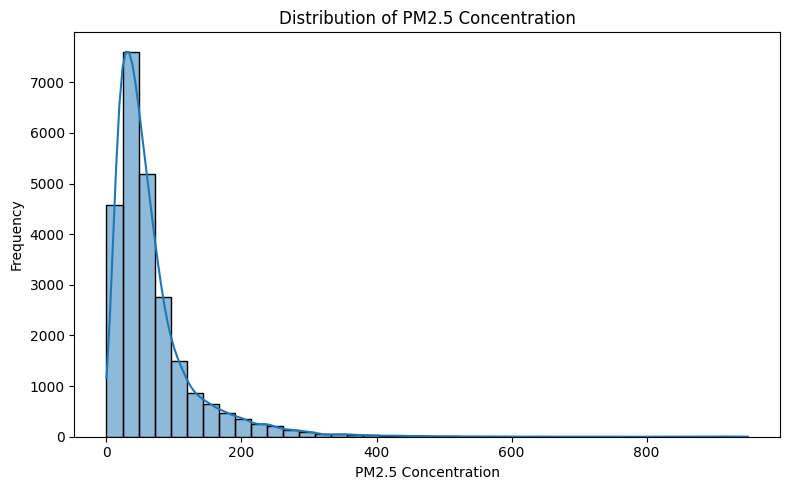

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["PM2.5"].dropna(), bins=40, kde=True)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

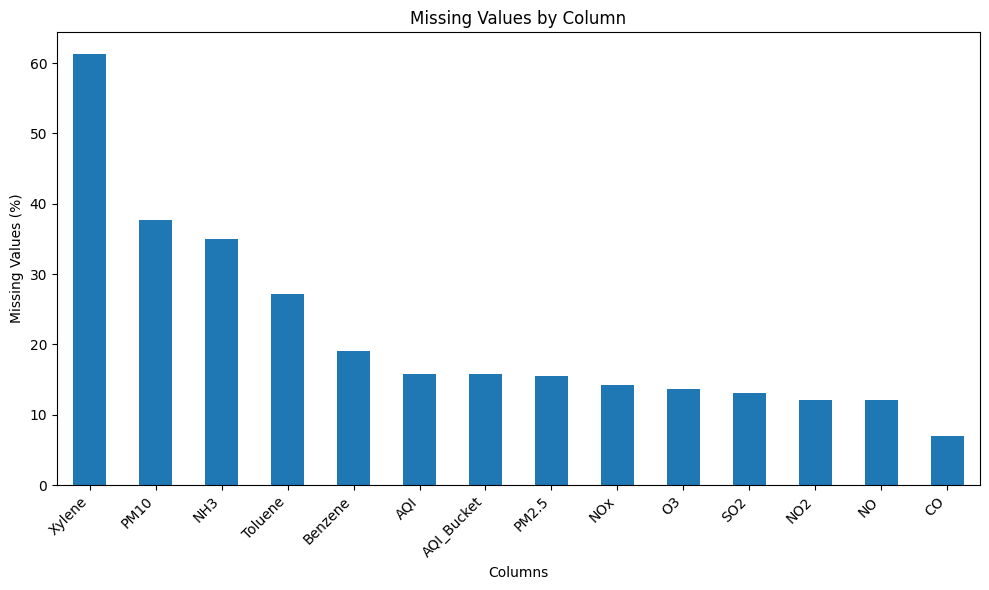

In [ ]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage > 0]

plt.figure(figsize=(10, 6))

missing_percentage.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Create a copy of the original dataset
data = df.copy()

# Remove duplicate records
print("Duplicates before cleaning:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicates after cleaning:", data.duplicated().sum())

# Remove rows where the target is missing
data = data.dropna(subset=["PM2.5"])

print("\nDataset shape after cleaning:", data.shape)

print("Missing PM2.5 values:", data["PM2.5"].isnull().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0

Dataset shape after cleaning: (24933, 16)
Missing PM2.5 values: 0


In [ ]:
# Select input features
features = [
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

# Define input features and target
X = data[features].copy()
y = data["PM2.5"].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
print(X.isnull().sum())

Input features shape: (24933, 11)
Target shape: (24933,)

Missing values in features:
PM10        7301
NO           351
NO2          377
NOx         1470
NH3         6644
CO           370
SO2          505
O3           752
Benzene     3151
Toluene     5555
Xylene     15273
dtype: int64


In [ ]:
# Convert Date to datetime
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Remove records with invalid dates
data = data.dropna(subset=["Date"])

# Sort observations chronologically
data = data.sort_values("Date").reset_index(drop=True)

# Select the same features and target
X = data[features].copy()
y = data["PM2.5"].copy()

# Use the earliest 80% for training and latest 20% for testing
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining date range:")
print(data["Date"].iloc[0], "to", data["Date"].iloc[split_index - 1])

print("\nTesting date range:")
print(data["Date"].iloc[split_index], "to", data["Date"].iloc[-1])

Training features: (19946, 11)
Testing features: (4987, 11)

Training date range:
2015-01-01 00:00:00 to 2019-12-09 00:00:00

Testing date range:
2019-12-09 00:00:00 to 2020-07-01 00:00:00


In [ ]:
from sklearn.impute import SimpleImputer

# Create the imputer
imputer = SimpleImputer(strategy="median")

# Learn medians from training data
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=features,
    index=X_train.index
)

# Apply the same medians to testing data
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=features,
    index=X_test.index
)

print("Missing values in training data:",
      X_train_imputed.isnull().sum().sum())

print("Missing values in testing data:",
      X_test_imputed.isnull().sum().sum())

print("\nTraining data is ready!")
print("Testing data is ready!")

Missing values in training data: 0
Missing values in testing data: 0

Training data is ready!
Testing data is ready!


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Models and evaluation metrics imported successfully!")

Models and evaluation metrics imported successfully!


In [ ]:
# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_imputed, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_imputed)

print("Random Forest training completed!")
print("Number of predictions:", len(rf_predictions))

Random Forest training completed!
Number of predictions: 4987


In [ ]:
# Create the XGBoost model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_imputed, y_train)

# Make predictions
xgb_predictions = xgb_model.predict(X_test_imputed)

print("XGBoost training completed!")
print("Number of predictions:", len(xgb_predictions))

XGBoost training completed!
Number of predictions: 4987


In [ ]:
# Function to evaluate a model
def evaluate_model(y_actual, y_predicted):
    mae = mean_absolute_error(y_actual, y_predicted)

    rmse = np.sqrt(
        mean_squared_error(y_actual, y_predicted)
    )

    r2 = r2_score(y_actual, y_predicted)

    return mae, rmse, r2


# Evaluate Random Forest
rf_mae, rf_rmse, rf_r2 = evaluate_model(
    y_test, rf_predictions
)

# Evaluate XGBoost
xgb_mae, xgb_rmse, xgb_r2 = evaluate_model(
    y_test, xgb_predictions
)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

print("\nXGBOOST RESULTS")
print("---------------------")
print("MAE:", round(xgb_mae, 3))
print("RMSE:", round(xgb_rmse, 3))
print("R2 Score:", round(xgb_r2, 3))

RANDOM FOREST RESULTS
---------------------
MAE: 14.227
RMSE: 24.39
R2 Score: 0.638

XGBOOST RESULTS
---------------------
MAE: 15.826
RMSE: 26.382
R2 Score: 0.576


In [ ]:
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [rf_mae, xgb_mae],
    "RMSE": [rf_rmse, xgb_rmse],
    "R2 Score": [rf_r2, xgb_r2]
})

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Random Forest,14.227,24.390,0.638
1,XGBoost,15.826,26.382,0.576


In [ ]:
print("Comparison of model performance")
print("--------------------------------")

if rf_mae < xgb_mae:
    print("Random Forest has the lower MAE.")
elif xgb_mae < rf_mae:
    print("XGBoost has the lower MAE.")
else:
    print("Both models have the same MAE.")

if rf_rmse < xgb_rmse:
    print("Random Forest has the lower RMSE.")
elif xgb_rmse < rf_rmse:
    print("XGBoost has the lower RMSE.")
else:
    print("Both models have the same RMSE.")

if rf_r2 > xgb_r2:
    print("Random Forest has the higher R2 score.")
elif xgb_r2 > rf_r2:
    print("XGBoost has the higher R2 score.")
else:
    print("Both models have the same R2 score.")

Comparison of model performance
--------------------------------
Random Forest has the lower MAE.
Random Forest has the lower RMSE.
Random Forest has the higher R2 score.


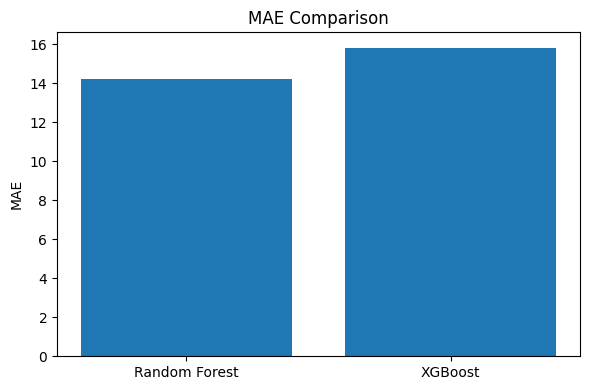

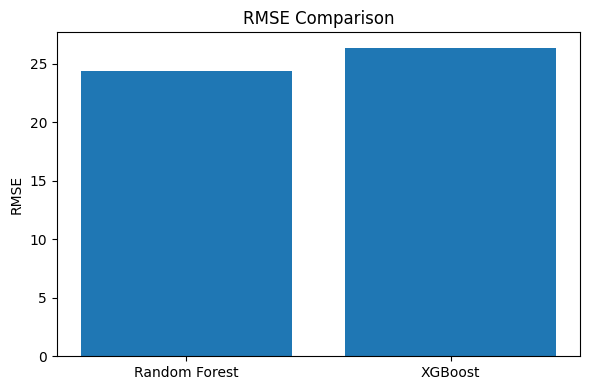

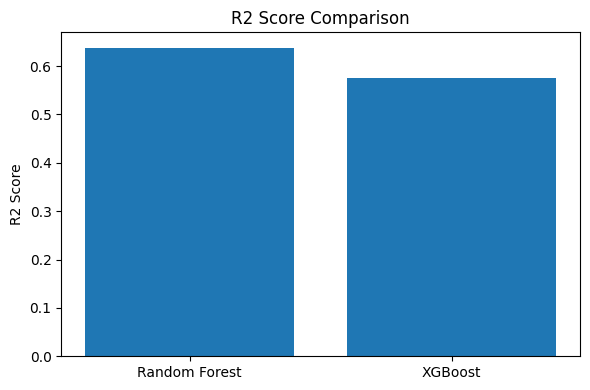

In [ ]:
metrics = ["MAE", "RMSE", "R2 Score"]

rf_values = [rf_mae, rf_rmse, rf_r2]
xgb_values = [xgb_mae, xgb_rmse, xgb_r2]

for i, metric in enumerate(metrics):
    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Random Forest", "XGBoost"],
        [rf_values[i], xgb_values[i]]
    )

    plt.title(f"{metric} Comparison")
    plt.ylabel(metric)
    plt.tight_layout()

    plt.savefig(f"{metric.lower().replace(' ', '_')}_comparison.png")
    plt.show()

In [ ]:
results.to_csv("model_comparison_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [ ]:
display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Random Forest,14.2265,24.3899,0.6377
1,XGBoost,15.8262,26.3820,0.5761


In [ ]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>